In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

In [10]:
def split_levels(x):
    if ':' in x:
        l1, l2 = x.split(':', 1)
        return pd.Series([l1.strip(), l2.strip()])
    else:
        return pd.Series([x.strip(), None])

def two_level_barh(df, col, xlabel=None, ylabel=None):

    df[f"M_{col}"] = df[col].apply(lambda x: x.split(", "))

    exploded = df[f"M_{col}"].explode()
    exploded = exploded.apply(split_levels)
    exploded.columns = ['Level1', 'Level2']
    exploded['Level2'] = exploded['Level2'].fillna('Absent')

    counts = exploded.groupby(['Level1', 'Level2']).size().unstack(fill_value=0)
    totals = counts.sum(axis=1)
    counts = counts.loc[totals.sort_values(ascending=True).index]

    counts.plot(
        kind='barh',
        stacked=True,
    )
    if xlabel is not None:
        plt.xlabel(xlabel)
    if ylabel is not None:
        plt.ylabel(ylabel)

In [11]:
# read and process dataset

# path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx - TextReading_Included.csv"
# df = pd.read_csv(path, usecols={"topic": str, "Title": str, "Year": int, "Source": str})

path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx"

df = pd.read_excel(path, sheet_name="TextReading_Included")

df = df[df.topic.notna()]
df.reset_index(drop=True, inplace=True)

df.topic = df.topic.apply(lambda x: x.split(", "))
df.Year = df.Year.astype(int)
df

,topic,Detailed GP,Title,Year,Source,Unnamed: 5,Pre processing outside generative model,Core Generative Paradigm,Dataset,Unnamed: 9,...,Ultimate Output semantics,Unnamed: 17,Generalizability,User Studies,AF: Human-likeness,AF: Alignment-to-input,AF: Normative compliance,AF: Intrinsic,COMBINED,Ablation study (none if empty)
0,"[Model, Dataset, Evaluation]",Discriminators,Complex layout generation for large-scale floo...,2025,Scopus,NaN,Retriever: graph,Discriminative,"RPLAN, P-PLAN",NaN,...,room function and contour,NaN,Absent,Absent,Pixel-level accuracy?,Absent,Absent,"RAI (Room Accessibility Index), Space Property...",NaN,yes
1,"[Model, Dataset]",NaN,Automated building layout generation using dee...,2023,Scopus,NaN,"Retriever: graph, Modifier: graph",Discriminative,GeLayout,NaN,...,walls,NaN,Absent,Intrinsic evaluation,"IoU, mIoU, Pixel-level accuracy?",Absent,Absent,Absent,NaN,NaN
2,[Model],NaN,FLNet: Graph Constrained Floor Layout Generation,2022,Scopus,NaN,Absent,Discriminative,RPLAN,NaN,...,"room function and contour, walls, entrance doo...",NaN,Absent,Realism,"FID (Quality), IoU",Absent,Absent,Absent,NaN,NaN
3,[Model],NaN,Skip-Connected Neural Networks with Layout Gra...,2023,arXiv,NaN,Absent,Discriminative,MSD,NaN,...,"room function and contour, walls",NaN,Absent,Absent,IoU (CVAAD),Absent,Absent,Absent,NaN,NaN
4,[Model],Discriminators (Stacked),FlexPlan: High-flexibility interactive floorpl...,2025,Scopus,NaN,Retriever: floorplan,Discriminative,RPLAN,NaN,...,"room function and contour, walls, interior doo...",NaN,external validation: new geometry,Intrinsic evaluation,FID (Similarity),Absent,Absent,Absent,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,[Dataset],NaN,MSD: A Benchmark Dataset for Floor Plan Genera...,2025,Scopus,NaN,Absent,Multiple Models,MSD,NaN,...,Multiple Models,NaN,Absent,Absent,"Mean IoU, Graph Compatibility",Absent,Absent,Absent,NaN,yes
68,"[Dataset, Evaluation]",NaN,The impact of architecturally qualified data i...,2024,Scopus,NaN,Absent,Multiple Models,"RPLAN, PUBLICPLAN",NaN,...,Multiple Models,NaN,Absent,"Realism, Ranking",Absent,Absent,Absent,Absent,NaN,NaN
69,[Evaluation],NaN,The Possibilities of Text-to-Image Tools for t...,2024,Scopus,NaN,Absent,Diffusion,Custom,NaN,...,"room function and contour, walls, interior doo...",NaN,Absent,Absent,Absent,Absent,Absent,Absent,NaN,NaN
70,[Evaluation],NaN,Quality assessment of residential layout desig...,2024,Scopus,NaN,Absent,GAN,RPLAN,NaN,...,"room function and contour, walls, interior doo...",NaN,Absent,Absent,"U test (room size proportions), U test (Visual...",Absent,Absent,Percent of isolated rooms,NaN,NaN


# RESULTS

### QUANTITY

In [12]:
# Figure: papers per Year

counts = df.groupby(['Year', 'Source']).size().unstack(fill_value=0)
counts = counts.sort_index()
counts

Source,Scopus,arXiv
Year,,
2019,1,0
2020,4,0
2021,1,0
2022,7,0
2023,8,4
2024,17,4
2025,24,2


<Axes: xlabel='Year', ylabel='# papers'>

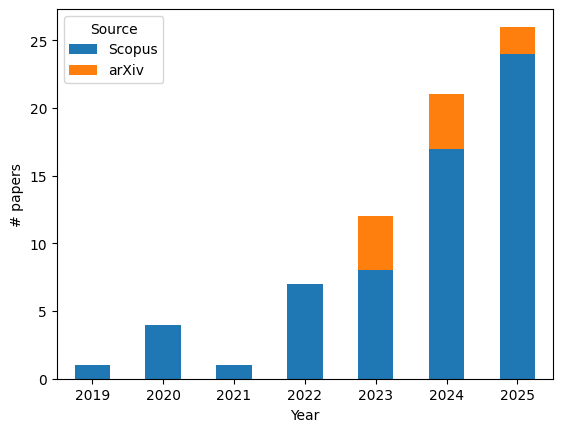

In [13]:
counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)

In [14]:
# Novelty

df.topic.value_counts().sort_index()

topic
[Dataset]                        1
[Dataset, Evaluation]            1
[Evaluation]                     5
[Model]                         54
[Model, Dataset]                 7
[Model, Dataset, Evaluation]     3
[Model, Evaluation]              1
Name: count, dtype: int64

### MODEL

In [15]:
df_model = df[df.topic.apply(lambda x: "Model" in x)]

Text(0, 0.5, 'ML model')

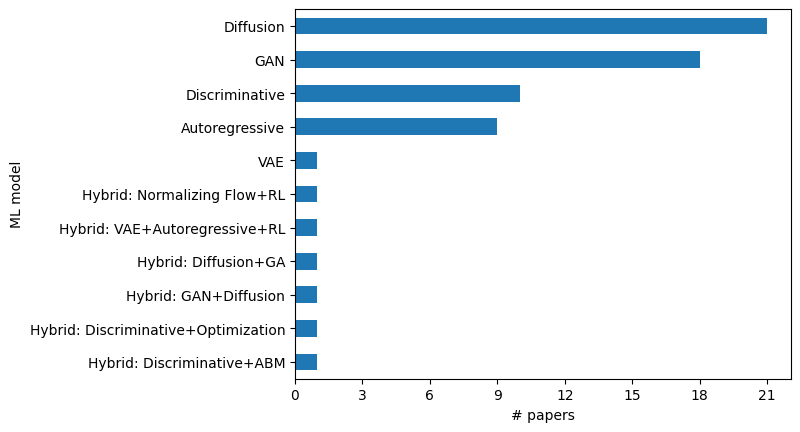

In [16]:
ax = df_model["Core Generative Paradigm"].value_counts(ascending=True).plot(kind="barh")
# ax.grid(axis="x")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("# papers")
ax.set_ylabel("ML model")


#### Discriminative vs Generative

In [17]:
df_model["Model Group"] = df_model["Core Generative Paradigm"].apply(lambda x: "Discriminative" if "Discriminative" in x else "Generative")
df_model["Model Group"].value_counts()

Model Group
Generative        53
Discriminative    12
Name: count, dtype: int64

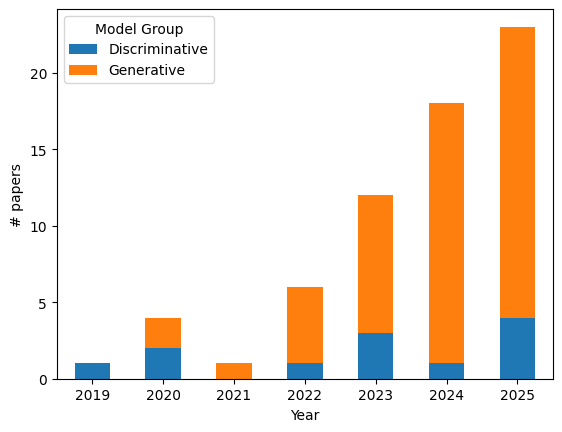

In [18]:
group_counts = df_model.groupby(['Year', 'Model Group']).size().unstack(fill_value=0)
group_counts = group_counts.sort_index()
group_counts

ax = group_counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)
# ax.grid(axis="y")

#### Discriminative Hybrid vs Generative Hybrid

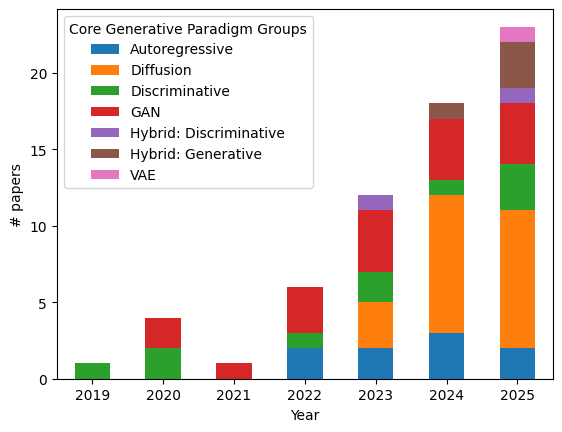

In [19]:
df_model["Core Generative Paradigm Groups"] = \
df_model["Core Generative Paradigm"].apply(lambda x: 
    "Hybrid: Discriminative" if ("Hybrid" in x and "Discriminative" in x) else 
    (
        "Hybrid: Generative" if "Hybrid" in x else x
    )
)

model_counts = df_model.groupby(['Year', 'Core Generative Paradigm Groups']).size().unstack(fill_value=0)
model_counts = model_counts.sort_index()

ax = model_counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)

In [50]:
# ax = df_model["Core Generative Paradigm Groups"].value_counts(ascending=True).plot(
#     kind="barh",
# )
# ax.grid(axis="x")
# ax.xaxis.set_major_locator(MaxNLocator(integer=True))

In [51]:
# df_hybrid = df_model[df_model["Core Generative Paradigm Groups"].isin(["Hybrid: Discriminative", "Hybrid: Generative"])]
# df_hybrid["Core Generative Paradigm"].value_counts().plot(kind="pie")

### POST PROCESSING

<Axes: xlabel='# papers', ylabel='Post-processing technique'>

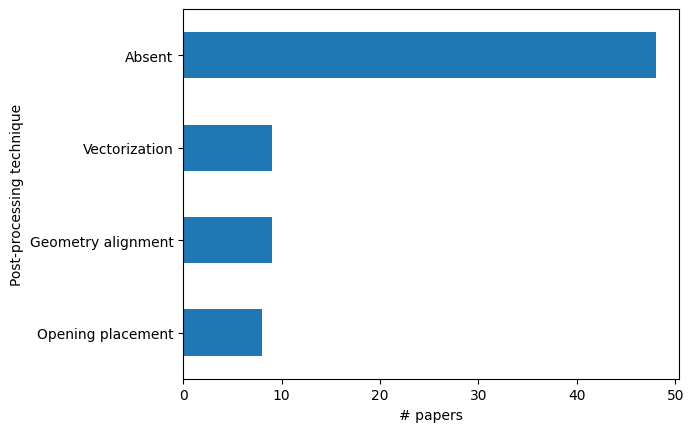

In [20]:
df_model["postprocessing"] = df_model["Post processing outside generative model"].apply(lambda x: x.split(", "))
df_model["postprocessing"].explode().value_counts(ascending=True).plot(kind="barh", xlabel="# papers", ylabel="Post-processing technique")

### PRE PROCESSING

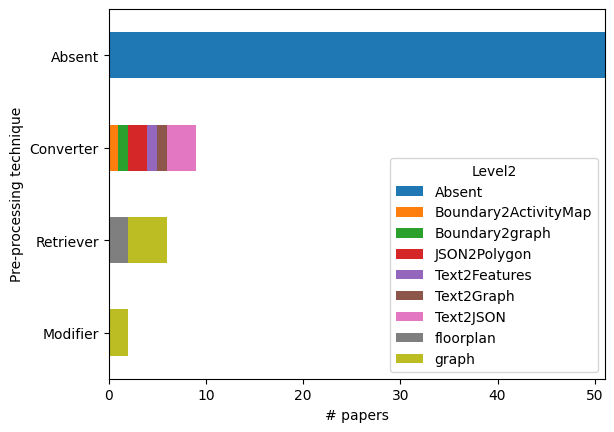

In [21]:
# df_model["preprocessing"] = df_model["Pre processing outside generative model"].apply(lambda x: x.split(", "))
# df_model["preprocessing"].explode().value_counts(ascending=True).plot(kind="pie")

two_level_barh(df_model, "Pre processing outside generative model", xlabel="# papers", ylabel="Pre-processing technique")

In [ ]:
///

### CONDITIONING INPUTS

In [23]:
df_model["input"] = df_model["Neural Input (modality: semantics)"].apply(lambda x: set(x.split(", ")))
df_model["input_modality"] = df_model["input"].apply(lambda x: set(i.split(": ")[0] for i in x))
df_model["input_semantics"] = df_model["input"].apply(lambda x: set(i.split(": ")[1] for i in x if i != "Absent"))


<Axes: ylabel='input_modality'>

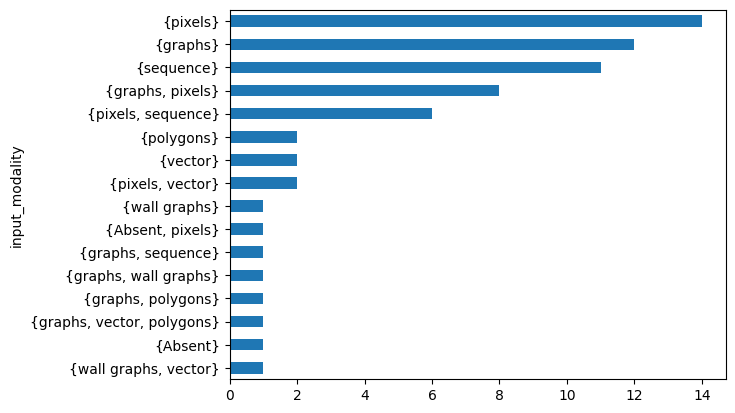

In [24]:
df_model["input_modality"].value_counts(ascending=True).plot(kind="barh")

<Axes: ylabel='input_semantics'>

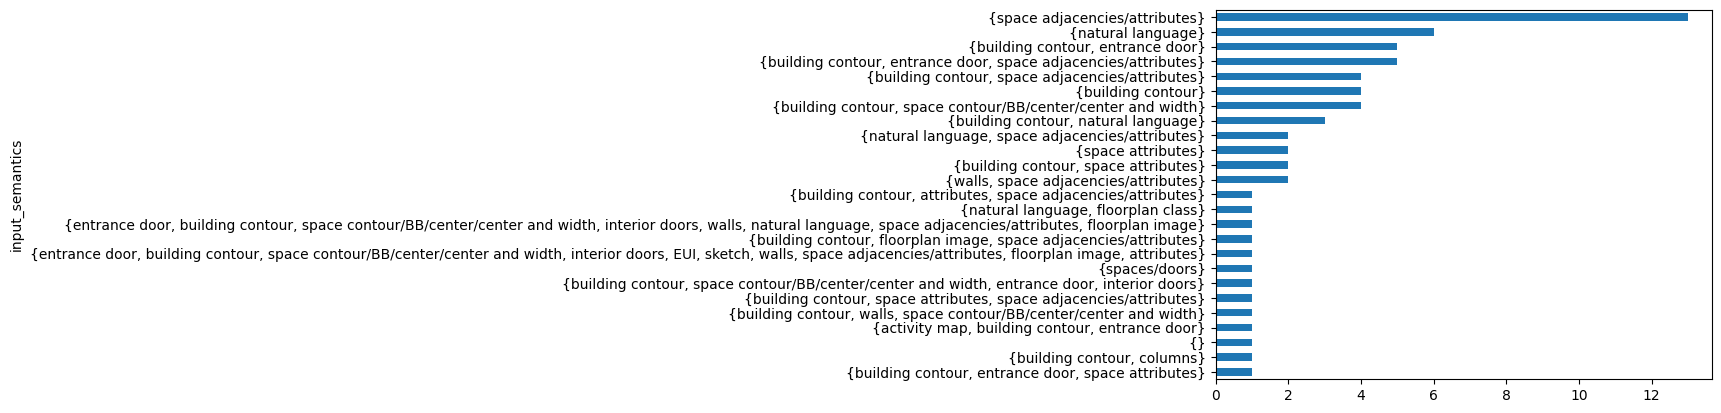

In [25]:
df_model["input_semantics"].value_counts(ascending=True).plot(kind="barh")

#### unqiue values

<Axes: xlabel='# papers', ylabel='Input -- modality: semantics'>

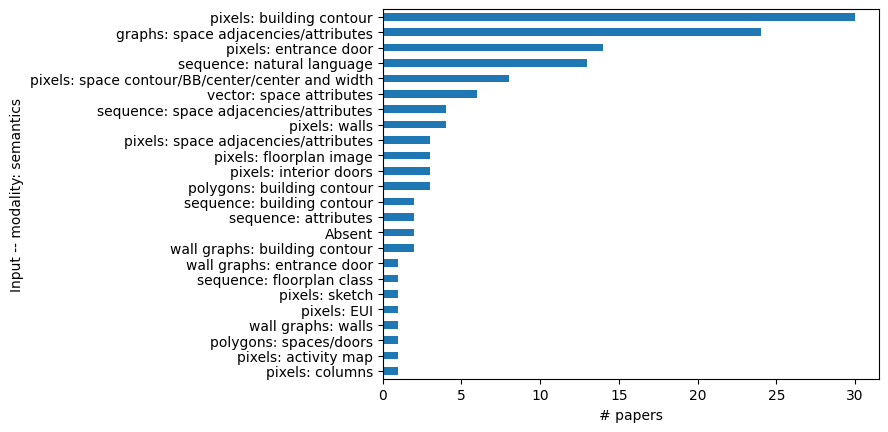

In [26]:
# redundant

df_model["input"] = df_model["Neural Input (modality: semantics)"].apply(lambda x: set(x.split(", ")))
df_model["input"].explode().value_counts(ascending=True).plot(kind="barh", xlabel="# papers", ylabel="Input -- modality: semantics")

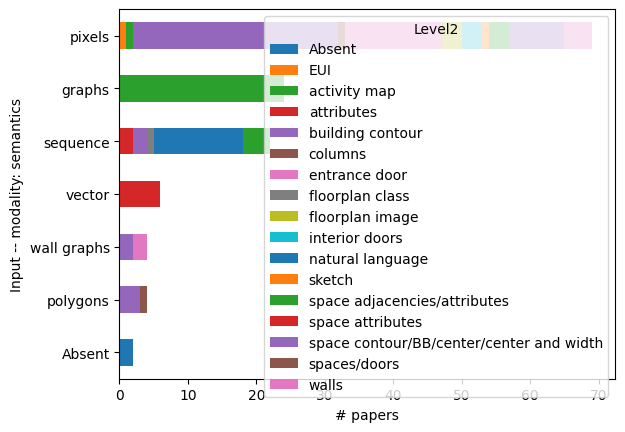

In [27]:
# replace with cooccurrence matrix or Sankey diagram (the last one!)

two_level_barh(df_model, "Neural Input (modality: semantics)", xlabel="# papers", ylabel="Input -- modality: semantics")

#### combinations

In [28]:
# modalities

# semantics

### OUTPUT MODALITY

<Axes: xlabel='# papers', ylabel='Output modality'>

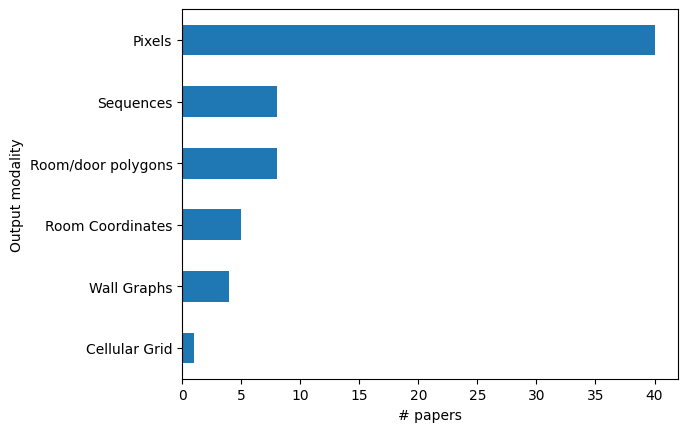

In [29]:
# ready to comment out

df_model["output_modality"] = df_model["Neural Output (modality)"].apply(lambda x: x.split(", "))
df_model["output_modality"].explode().value_counts(ascending=True).plot(kind="barh", xlabel="# papers", ylabel="Output modality")

# df_model["output_modality"].value_counts(ascending=True).plot(kind="barh", xlabel="# papers", ylabel="Output modality")


### OUTPUT SEMANTICS

<Axes: xlabel='# papers', ylabel='Output modality'>

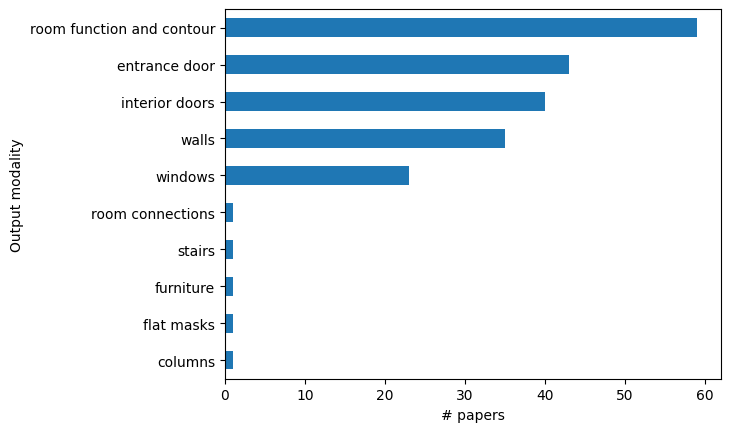

In [30]:
# ready to comment out

df_model["output_semantics"] = df_model["Ultimate Output semantics"].apply(lambda x: set(x.split(", ")))
df_model["output_semantics"].explode().value_counts(ascending=True).plot(kind="barh", xlabel="# papers", ylabel="Output modality")

<Axes: ylabel='output_semantics'>

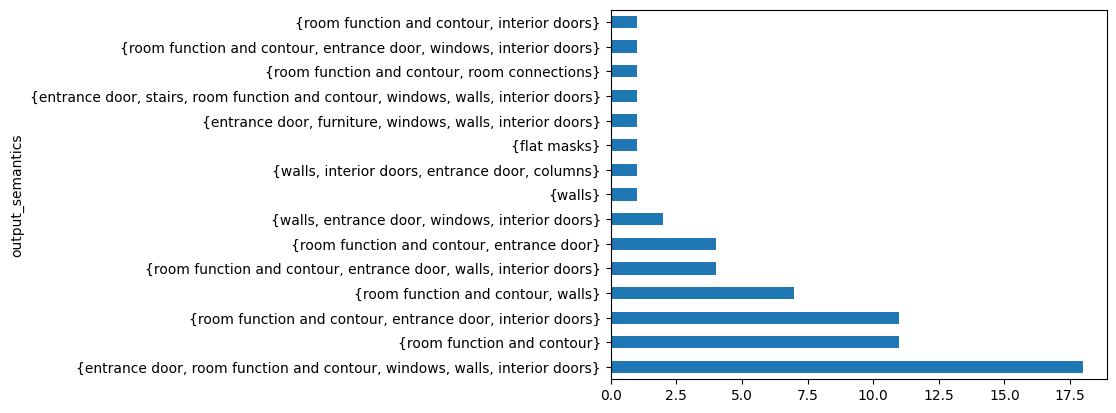

In [31]:
df_model["output_semantics"].value_counts().plot(kind="barh")

### INPUT --> OUTPUT

#### MODALITY --> MODALITY

In [ ]:
# combinations --> combinations

#### SEMANTICS --> SEMANTICS

In [ ]:
# combinations --> combinations

In [32]:
df_model['input_semantics'].apply(lambda x: tuple(sorted(x)))

0     (building contour, entrance door, space adjace...
1     (building contour, space contour/BB/center/cen...
2     (building contour, entrance door, space adjace...
3                 (space adjacencies/attributes, walls)
4                  (building contour, space attributes)
                            ...                        
60                    (building contour, entrance door)
61                      (space adjacencies/attributes,)
62                  (floorplan class, natural language)
63    (attributes, building contour, space adjacenci...
64                    (building contour, entrance door)
Name: input_semantics, Length: 65, dtype: object

In [33]:
df_model['output_semantics'].apply(lambda x: tuple(sorted(x)))

0                          (room function and contour,)
1                                              (walls,)
2     (entrance door, interior doors, room function ...
3                    (room function and contour, walls)
4     (entrance door, interior doors, room function ...
                            ...                        
60    (entrance door, interior doors, room function ...
61    (entrance door, interior doors, room function ...
62    (entrance door, interior doors, room function ...
63    (entrance door, interior doors, room function ...
64          (interior doors, room function and contour)
Name: output_semantics, Length: 65, dtype: object

In [34]:
def set_to_label(x):
    return " + ".join(sorted(x)) if len(x) > 0 else "empty"

matrix = pd.crosstab(
    df_model['input_semantics'].apply(set_to_label),
    df_model['output_semantics'].apply(set_to_label),
)

matrix 

output_semantics,columns + entrance door + interior doors + walls,entrance door + furniture + interior doors + walls + windows,entrance door + interior doors + room function and contour,entrance door + interior doors + room function and contour + stairs + walls + windows,entrance door + interior doors + room function and contour + walls,entrance door + interior doors + room function and contour + walls + windows,entrance door + interior doors + room function and contour + windows,entrance door + interior doors + walls + windows,entrance door + room function and contour,flat masks,interior doors + room function and contour,room connections + room function and contour,room function and contour,room function and contour + walls,walls
input_semantics,,,,,,,,,,,,,,,
EUI + attributes + building contour + entrance door + floorplan image + interior doors + sketch + space adjacencies/attributes + space contour/BB/center/center and width + walls,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
activity map + building contour + entrance door,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
attributes + building contour + space adjacencies/attributes,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
building contour,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0
building contour + columns,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
building contour + entrance door,0,0,0,0,1,2,0,0,0,0,1,0,0,1,0
building contour + entrance door + floorplan image + interior doors + natural language + space adjacencies/attributes + space contour/BB/center/center and width + walls,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
building contour + entrance door + interior doors + space contour/BB/center/center and width,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
building contour + entrance door + space adjacencies/attributes,0,0,0,0,0,3,0,0,1,0,0,0,1,0,0


In [35]:
df_model['input_semantics'] = df_model['input_semantics'].apply(set_to_label)
df_model['output_semantics']= df_model['output_semantics'].apply(set_to_label)

# cooc = (
#     df
#     .groupby(['input_semantics', 'output_semantics'])
#     .size()
#     .reset_index(name='Count')
# )

# cooc

In [36]:
df_model['input_semantics']

0     building contour + entrance door + space adjac...
1     building contour + space contour/BB/center/cen...
2     building contour + entrance door + space adjac...
3                  space adjacencies/attributes + walls
4                   building contour + space attributes
                            ...                        
60                     building contour + entrance door
61                         space adjacencies/attributes
62                   floorplan class + natural language
63    attributes + building contour + space adjacenc...
64                     building contour + entrance door
Name: input_semantics, Length: 65, dtype: str

In [37]:
df_model['output_semantics']

0                             room function and contour
1                                                 walls
2     entrance door + interior doors + room function...
3                     room function and contour + walls
4     entrance door + interior doors + room function...
                            ...                        
60    entrance door + interior doors + room function...
61    entrance door + interior doors + room function...
62    entrance door + interior doors + room function...
63    entrance door + interior doors + room function...
64           interior doors + room function and contour
Name: output_semantics, Length: 65, dtype: str

In [38]:
cooc = (
    df_model
    .groupby(['input_semantics', 'output_semantics'])
    .size()
    .reset_index(name='Count')
).sort_values("Count", ascending=False)

cooc.to_csv("cooc.csv")

In [42]:
import pandas as pd
import plotly.graph_objects as go

df = pd.read_csv("cooc.csv")

# Keep only needed columns
df = df[["input_semantics", "output_semantics", "Count"]]

# Optional: remove tiny flows if diagram is too crowded
# df = df[df["Count"] >= 2]

sources = df["input_semantics"].astype(str)
targets = df["output_semantics"].astype(str)
values = df["Count"]

# Create unique node list
nodes = pd.Index(pd.concat([sources, targets]).unique())

# Map labels to numeric IDs
source_ids = sources.map(nodes.get_loc)
target_ids = targets.map(nodes.get_loc)

fig = go.Figure(data=[go.Sankey(
    node=dict(
        label=nodes.tolist(),
        pad=15,
        thickness=18
    ),
    link=dict(
        source=source_ids,
        target=target_ids,
        value=values
    )
)])

fig.update_layout(
    title_text="Input semantics → Output semantics",
    font_size=10,
    width=1200,
    height=800
)

# fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'link': {'source': {'bdata': 'AAECAAMEAAUGBwgJCgoLDAENDgQEBAoPChADAQcRAxITFBUCFhYFBRcXBQUAAAAY',
                                  'dtype': 'i1'},
                       'target': {'bdata': 'GRoaGxkaGhscHRsaGRsaHh0eGhweHxwgIRkcGxoeIhojJBwlGxoZJhsaGh0nJBwZ',
                                  'dtype': 'i1'},
                       'value': {'bdata': 'BQMDAwICAgICAgIBAQEBAQEBAQEBAQEBAQEBAQEBAQEBAQEBAQEBAQEBAQEBAQEB',
                                 'dtype': 'i1'}},
              'node': {'label': [space adjacencies/attributes, building contour +
                                 entrance door + space adjacencies/attributes,
                                 building contour + space contour/BB/center/center
                                 and width, building contour + space
                                 adjacencies/attributes, building contour +
                                 entrance door, natural language, space
                                 adjacencies/attributes + walls, building contour +
                                 natural language, space attributes, EUI +
                                 attributes + building contour + entrance door +
                                 floorplan image + interior doors + sketch + space
                                 adjacencies/attributes + space
                                 contour/BB/center/center and width + walls,
                                 building contour, attributes + building contour +
                                 space adjacencies/attributes, activity map +
                                 building contour + entrance door, building contour
                                 + entrance door + interior doors + space
                                 contour/BB/center/center and width, building
                                 contour + entrance door + floorplan image +
                                 interior doors + natural language + space
                                 adjacencies/attributes + space
                                 contour/BB/center/center and width + walls,
                                 building contour + columns, building contour +
                                 space adjacencies/attributes + space attributes,
                                 building contour + floorplan image + space
                                 adjacencies/attributes, building contour +
                                 entrance door + space attributes, floorplan class
                                 + natural language, empty, building contour +
                                 space contour/BB/center/center and width + walls,
                                 building contour + space attributes, natural
                                 language + space adjacencies/attributes,
                                 spaces/doors, entrance door + interior doors +
                                 room function and contour, entrance door +
                                 interior doors + room function and contour + walls
                                 + windows, room function and contour, room
                                 function and contour + walls, entrance door + room
                                 function and contour, entrance door + interior
                                 doors + room function and contour + walls,
                                 interior doors + room function and contour,
                                 columns + entrance door + interior doors + walls,
                                 entrance door + furniture + interior doors + walls
                                 + windows, room connections + room function and
                                 contour, entrance door + interior doors + room
                                 function and contour + windows, entrance door +
                                 interior doors + walls + windows, walls, entrance
                                 door + interior doors + r

### DATASET

In [44]:
df["dataset"] = df["Dataset"].apply(lambda x: x.split(", "))

dataset_exploded = df.explode("dataset")
dataset_exploded["dataset"].value_counts(ascending=True).plot(kind="barh", xlabel="# papers")

KeyError: 'Dataset'

<Axes: xlabel='# papers', ylabel='dataset_grouped'>

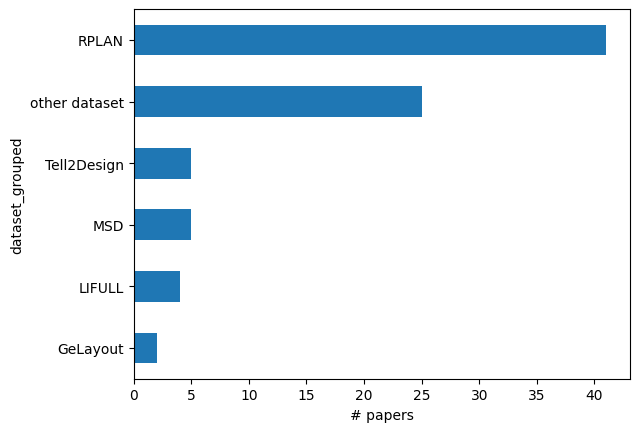

In [21]:
dataset_exploded["dataset_grouped"] = dataset_exploded.dataset.apply(lambda x: x if x in ["LIFULL", "RPLAN", "GeLayout", "MSD", "Tell2Design"] else "other dataset")
dataset_exploded["dataset_grouped"].value_counts(ascending=True).plot(kind="barh", xlabel="# papers")

In [22]:
unique_ds_list = [
    d for d in dataset_exploded["dataset"].unique() if d not in ["LIFULL", "RPLAN", "GeLayout", "MSD", "Tell2Design"]
]

unique_ds = pd.DataFrame(
    data=unique_ds_list, 
    columns=["dataset"]
).sort_values(by="dataset").reset_index(drop=True)

unique_ds.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
dataset,ArchiMetricsNet,Custom,DS2D,GreenPD,Huang and Zheng 2018,LLAMA,Liu Wu et al 2017,MRED-14,Multi-RP,NM-RPLAN,P-PLAN,PUBLICPLAN,ResPlan,Solar Decathlon,Tell2Floorplan,pseudo-floor-plan-12k


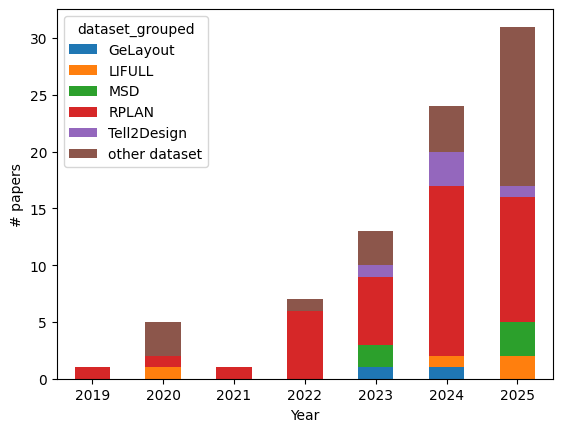

In [23]:
def merge_datasets(x):
    groups = ["LIFULL", "RPLAN", "GeLayout", "MSD", "Tell2Design"]
    return x if x in groups else "other dataset"

dataset_exploded["dataset_grouped"] = dataset_exploded["dataset"].apply(merge_datasets)

dataset_counts = (
    dataset_exploded
    .groupby(['Year', 'dataset_grouped'])
    .size()
    .unstack(fill_value=0)
)

ax = dataset_counts.plot(
    kind='bar',
    stacked=True,
    ylabel='# papers',
    # figsize=(12,6)
)
ax.tick_params(axis='x', rotation=0)

### GENERALIZABILITY

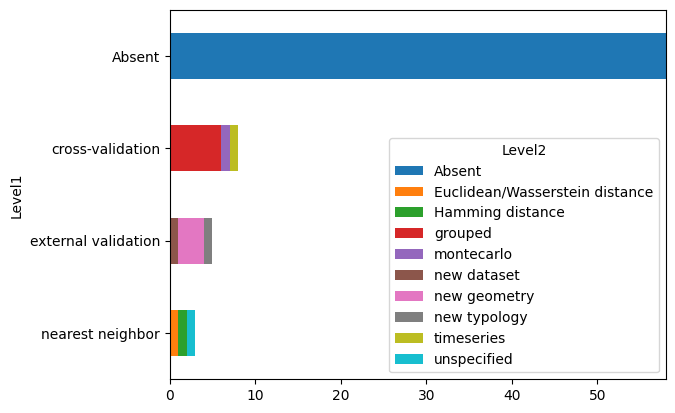

In [24]:
two_level_barh(df, "Generalizability")